# 01 - Exploratory Data Analysis
HMEQ home-equity loan data. Target `BAD` = 1 means the applicant defaulted or was seriously delinquent.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
def save(name):
    plt.tight_layout(); plt.savefig(config.FIGURES_DIR / name, dpi=110); plt.show()
raw = pd.read_csv(config.DATA_PATH)
print(raw.shape)
raw.dtypes.to_frame('dtype').join(raw.nunique().rename('unique'))

(5960, 13)


,dtype,unique
BAD,int64,2
LOAN,int64,540
MORTDUE,float64,5053
VALUE,float64,5381
REASON,str,2
JOB,str,6
YOJ,float64,99
DEROG,float64,11
DELINQ,float64,14
CLAGE,float64,5314


In [2]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BAD,5960.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00
LOAN,5960.0,18607.97,11207.48,1100.00,11100.00,16300.00,23300.00,89900.00
MORTDUE,5442.0,73760.82,44457.61,2063.00,46276.00,65019.00,91488.00,399550.00
VALUE,5848.0,101776.05,57385.78,8000.00,66075.50,89235.50,119824.25,855909.00
YOJ,5445.0,8.92,7.57,0.00,3.00,7.00,13.00,41.00
DEROG,5252.0,0.25,0.85,0.00,0.00,0.00,0.00,10.00
DELINQ,5380.0,0.45,1.13,0.00,0.00,0.00,0.00,15.00
CLAGE,5652.0,179.77,85.81,0.00,115.12,173.47,231.56,1168.23
NINQ,5450.0,1.19,1.73,0.00,0.00,1.00,2.00,17.00
CLNO,5738.0,21.30,10.14,0.00,15.00,20.00,26.00,71.00


Column meanings inferred from names and value ranges: LOAN (requested amount), MORTDUE (mortgage still owed), VALUE (property value), REASON (DebtCon = debt consolidation, HomeImp = home improvement), JOB (category), YOJ (years at job), DEROG (major derogatory reports), DELINQ (delinquent credit lines), CLAGE (oldest credit line age in months), NINQ (recent inquiries), CLNO (number of credit lines), DEBTINC (debt-to-income ratio). There is no age, gender, race or income column.

Duplicate rows: 0


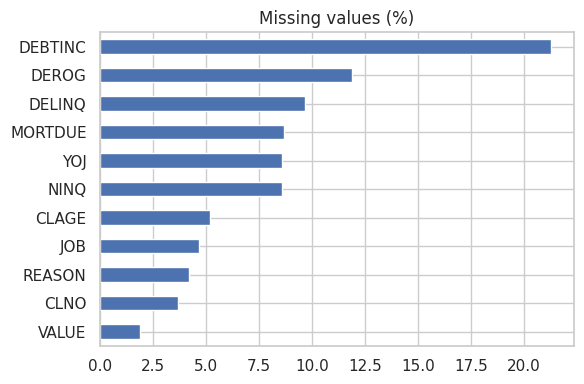

In [3]:
print('Duplicate rows:', raw.duplicated().sum())
miss = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
miss = miss[miss > 0]
miss.plot.barh(figsize=(6, 4), title='Missing values (%)')
plt.gca().invert_yaxis(); save('missing_values.png')

Every predictor except `LOAN` has missing values. `DEBTINC` is the worst at about 21%. No duplicate rows exist.

{0: 4771, 1: 1189} 19.95 % default


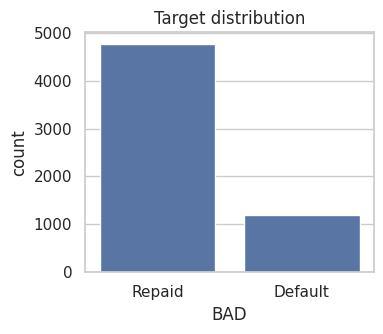

In [4]:
counts = raw.BAD.value_counts()
print(counts.to_dict(), (raw.BAD.mean() * 100).round(2), '% default')
fig, ax = plt.subplots(figsize=(4, 3.5))
sns.countplot(x='BAD', data=raw, ax=ax)
ax.set_xticklabels(['Repaid', 'Default']); ax.set_title('Target distribution'); save('target_distribution.png')

About 20% of applicants default, a 4 to 1 imbalance. A model that predicts 'repaid' for everyone would score about 80% accuracy while catching no defaulters, so accuracy alone is misleading. PR-AUC, recall and balanced accuracy are used instead.

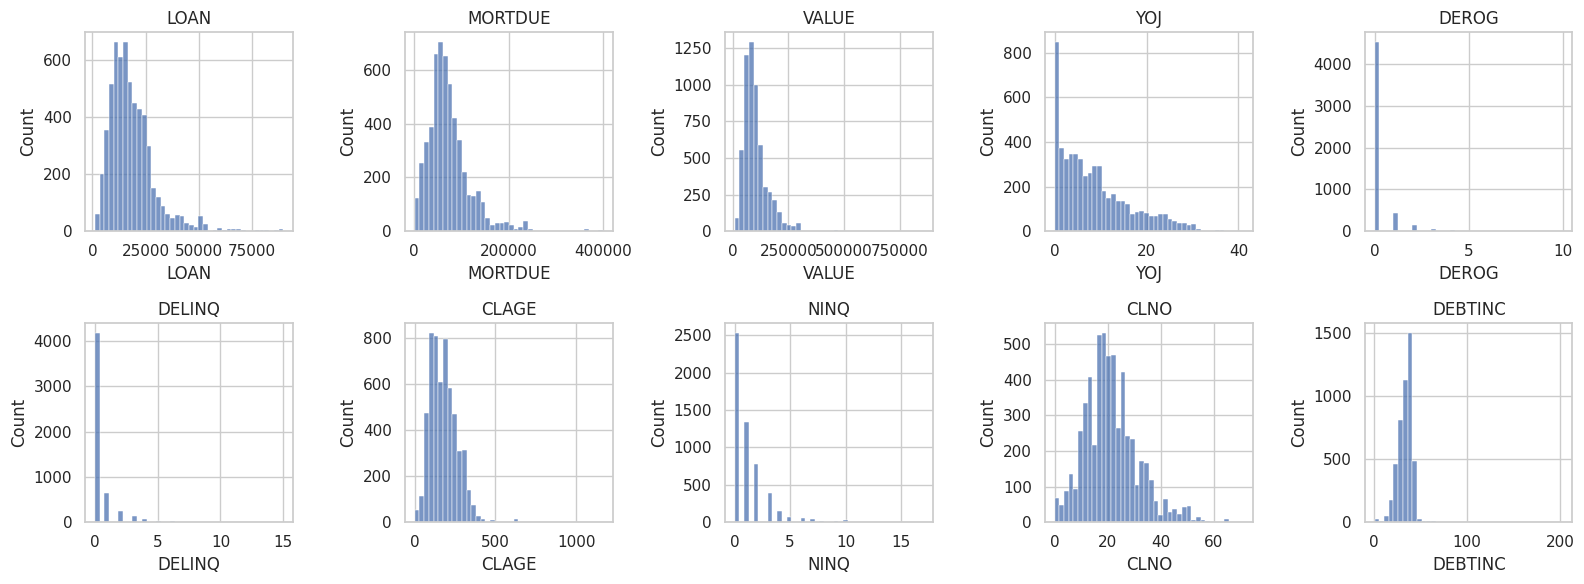

In [5]:
num = config.NUMERIC_COLS
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.ravel(), num):
    sns.histplot(raw[col].dropna(), bins=40, ax=ax); ax.set_title(col)
save('numeric_distributions.png')

`LOAN`, `MORTDUE` and `VALUE` are right-skewed, so log versions are engineered. `DEROG`, `DELINQ` and `NINQ` are mostly zero with a long tail.

In [6]:
def iqr_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); w = 1.5 * (q3 - q1)
    return ((s < q1 - w) | (s > q3 + w)).mean() * 100
print('Share of values outside 1.5 x IQR (%)')
raw[num].apply(iqr_outliers).round(1).sort_values(ascending=False).to_frame('outlier_pct')

Share of values outside 1.5 x IQR (%)


,outlier_pct
DELINQ,22.3
DEROG,13.8
VALUE,5.5
LOAN,4.3
MORTDUE,4.3
CLNO,3.8
NINQ,3.2
DEBTINC,2.0
YOJ,1.7
CLAGE,0.8


In [7]:
print(raw[raw.DEBTINC > 100][['BAD', 'DEBTINC']].to_string())

      BAD     DEBTINC
3910    1  143.949605
4423    1  133.528270
4473    1  203.312149
5599    1  114.050528
5912    1  144.189001


Many columns have heavy tails, but most look like real customers, not errors. The five `DEBTINC` values above 100 are all defaulters, so they are kept. Tree models ignore extreme values; for logistic regression the pipeline clips values at the 1st and 99th percentile learned on the training data.

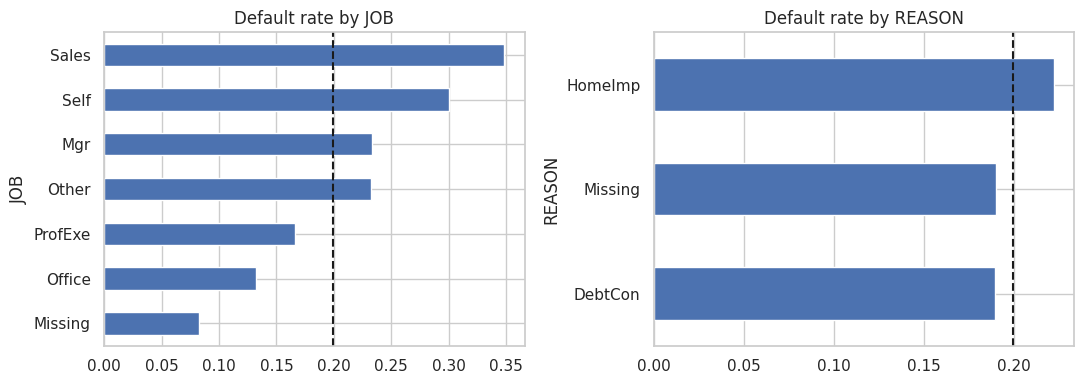

,mean,size
JOB,,
Mgr,0.233,767
Missing,0.082,279
Office,0.132,948
Other,0.232,2388
ProfExe,0.166,1276
Sales,0.349,109
Self,0.301,193


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['JOB', 'REASON']):
    rate = raw.assign(**{col: raw[col].fillna('Missing')}).groupby(col).BAD.agg(['mean', 'size'])
    rate['mean'].sort_values().plot.barh(ax=ax, title=f'Default rate by {col}')
    ax.axvline(raw.BAD.mean(), color='k', ls='--')
save('default_rate_categorical.png')
raw.assign(JOB=raw.JOB.fillna('Missing')).groupby('JOB').BAD.agg(['mean', 'size']).round(3)

Default rate differs by job group (Sales and Self-employed are high but have few applicants; Office is lowest). `REASON` matters much less.

In [9]:
rows = []
for col in raw.columns[1:]:
    m = raw[col].isna()
    if m.any(): rows.append({'column': col, 'missing_pct': m.mean() * 100, 'default_rate_if_missing': raw.BAD[m].mean(), 'default_rate_if_present': raw.BAD[~m].mean()})
mt = pd.DataFrame(rows).round(3).sort_values('default_rate_if_missing', ascending=False)
mt

,column,missing_pct,default_rate_if_missing,default_rate_if_present
1,VALUE,1.879,0.938,0.185
10,DEBTINC,21.258,0.620,0.086
7,CLAGE,5.168,0.253,0.197
9,CLNO,3.725,0.239,0.198
0,MORTDUE,8.691,0.205,0.199
2,REASON,4.228,0.190,0.200
8,NINQ,8.557,0.147,0.204
4,YOJ,8.641,0.126,0.206
6,DELINQ,9.732,0.124,0.208
5,DEROG,11.879,0.123,0.210


This is the most important finding. When `DEBTINC` is missing, about 62% of applicants default versus about 9% when it is present. When `VALUE` is missing, about 94% default. Missingness is not random noise, so missing-value indicators are added as features instead of only imputing.

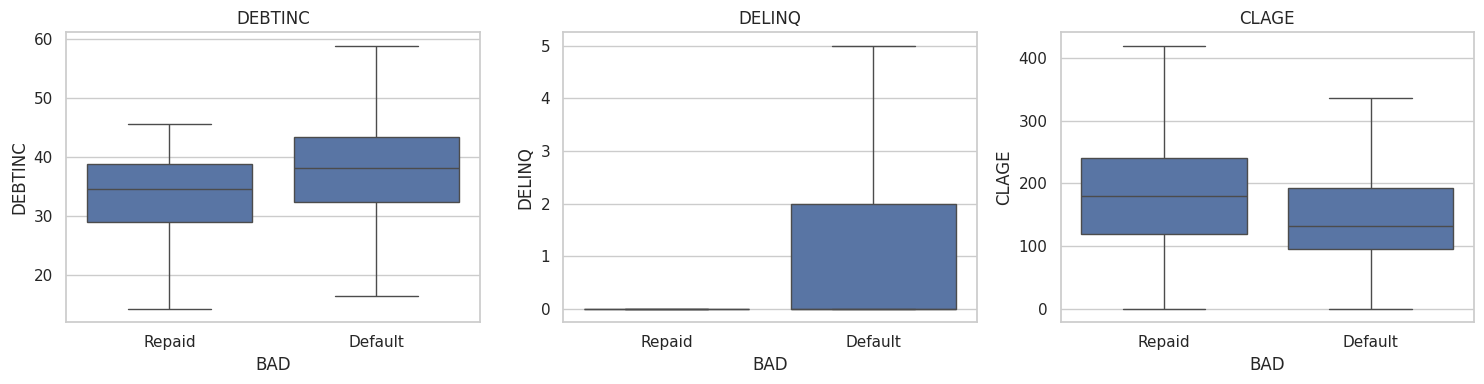

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['DEBTINC', 'DELINQ', 'CLAGE']):
    sns.boxplot(x='BAD', y=col, data=raw, ax=ax, showfliers=False); ax.set_xticklabels(['Repaid', 'Default']); ax.set_title(col)
save('key_features_by_target.png')

Defaulters have a higher median debt-to-income ratio (about 38 vs 35), a shorter median credit history (about 133 vs 180 months) and a heavier tail of delinquencies.

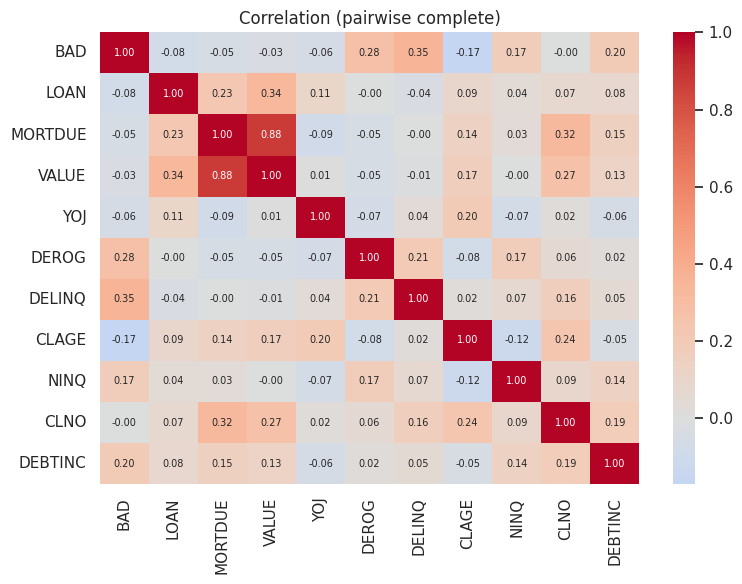

DELINQ     0.354
DEROG      0.276
DEBTINC    0.200
NINQ       0.175
CLNO      -0.004
VALUE     -0.030
MORTDUE   -0.048
YOJ       -0.060
LOAN      -0.075
CLAGE     -0.170
Name: BAD, dtype: float64

In [11]:
corr = raw[['BAD'] + num].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation (pairwise complete)'); save('correlation_heatmap.png')
corr.BAD.drop('BAD').sort_values(ascending=False).round(3)

`DELINQ`, `DEROG` and `DEBTINC` correlate most with default. `MORTDUE` and `VALUE` are strongly correlated with each other, which is why ratio features such as mortgage-to-value are used.

## Suspicious columns and possible leakage
- No column is a direct outcome of default, such as a collections status or recovery amount.
- The missingness pattern of `DEBTINC` and `VALUE` is suspiciously predictive. It may reflect how data was collected (for example, records of applicants already in trouble were less complete). If a real lender would not have these gaps at application time, the model would look better offline than in use. This is a limitation, discussed in the README.
- The dataset has no date column, so time-based validation is not possible.